# 1. CONTEXT AND RELEVANCE 


In [41]:
import pandas as pd
import numpy as np

df = pd.read_csv("Most Streamed Spotify Songs 2024.csv", encoding="latin-1")  # use YOUR exact file name
df_raw = df.copy()   # backup of the original, so we can always compare later
print(df.shape)


(4600, 29)


In [63]:
df.head()

,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,AirPlay Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Shazam Counts,Explicit Track,release_year,has_tiktok_data
0,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,2024-04-26,QM24S2402528,1,725.4,"390,470,936.0","30,716.0","196,631,588.0",...,"40,975.0",62.0,"17,598,718.0",114.0,"18,004,655.0","22,931.0","2,669,262.0",0,2024,True
1,Not Like Us,Not Like Us,Kendrick Lamar,2024-05-04,USUG12400910,2,545.9,"323,703,884.0","28,113.0","174,597,137.0",...,"40,778.0",67.0,"10,422,430.0",111.0,"7,780,028.0","28,444.0","1,118,279.0",1,2024,True
2,i like the way you kiss me,I like the way you kiss me,Artemas,2024-03-19,QZJ842400387,3,538.4,"601,309,283.0","54,331.0","211,607,669.0",...,"74,333.0",136.0,"36,321,847.0",172.0,"5,022,621.0","5,639.0","5,285,340.0",0,2024,True
3,Flowers,Flowers - Single,Miley Cyrus,2023-01-12,USSM12209777,4,444.9,"2,031,280,633.0","269,802.0","136,569,078.0",...,"1,474,799.0",264.0,"24,684,248.0",210.0,"190,260,277.0","203,384.0","11,822,942.0",0,2023,True
4,Houdini,Houdini,Eminem,2024-05-31,USUG12403398,5,423.3,"107,034,922.0","7,223.0","151,469,874.0",...,"12,185.0",82.0,"17,660,624.0",105.0,"4,493,884.0","7,006.0","457,017.0",1,2024,False


# 2. DATA QUALITY

In [57]:
missing = pd.DataFrame({
    "missing": df.isnull().sum(),
    "pct": (df.isnull().mean() * 100).round(1)
}).sort_values("pct", ascending=False)
missing

,missing,pct
Pandora Track Stations,1162,25.9
TikTok Posts,1081,24.1
Pandora Streams,1004,22.4
Amazon Playlist Count,950,21.2
YouTube Playlist Reach,930,20.7
TikTok Views,890,19.8
TikTok Likes,889,19.8
Deezer Playlist Reach,824,18.4
Deezer Playlist Count,817,18.2
Spotify Popularity,706,15.7


In [58]:
# Check for duplicates 
df.duplicated().sum()


np.int64(0)

In [59]:
df[df.duplicated(keep=False)]


,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,AirPlay Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Shazam Counts,Explicit Track,release_year,has_tiktok_data


In [60]:
# Remove duplicates
df = df.drop_duplicates()
df.shape


(4485, 28)

# 3. DATA TYPES

In [46]:
df.dtypes


Track                          object
Album Name                     object
Artist                         object
Release Date                   object
ISRC                           object
All Time Rank                  object
Track Score                   float64
Spotify Streams                object
Spotify Playlist Count         object
Spotify Playlist Reach         object
Spotify Popularity            float64
YouTube Views                  object
YouTube Likes                  object
TikTok Posts                   object
TikTok Likes                   object
TikTok Views                   object
YouTube Playlist Reach         object
Apple Music Playlist Count    float64
AirPlay Spins                  object
SiriusXM Spins                 object
Deezer Playlist Count         float64
Deezer Playlist Reach          object
Amazon Playlist Count         float64
Pandora Streams                object
Pandora Track Stations         object
Soundcloud Streams             object
Shazam Count

### Convert text columns to numbers

Remove the comma separators and convert to numeric. Missing counts are compared before and after to confirm no data was lost (the output should be empty).



In [52]:
num_cols = [
    "All Time Rank", "Spotify Streams", "Spotify Playlist Count", "Spotify Playlist Reach",
    "YouTube Views", "YouTube Likes", "TikTok Posts", "TikTok Likes", "TikTok Views",
    "YouTube Playlist Reach", "AirPlay Spins", "SiriusXM Spins", "Deezer Playlist Reach",
    "Pandora Streams", "Pandora Track Stations", "Soundcloud Streams", "Shazam Counts"
]
num_cols = [c for c in num_cols if c in df.columns]   # skips any column already dropped

before = df[num_cols].isnull().sum()

for col in num_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")

after = df[num_cols].isnull().sum()
print(after[after != before])   # should print nothing = no data was lost

Series([], dtype: int64)


### Convert Release Date to a date

Convert the text to a proper date and extract the release year for later analysis.

In [53]:
df["Release Date"] = pd.to_datetime(df["Release Date"], format="%m/%d/%Y")
df["release_year"] = df["Release Date"].dt.year

In [54]:
df.dtypes

Track                                 object
Album Name                            object
Artist                                object
Release Date                  datetime64[ns]
ISRC                                  object
All Time Rank                          int64
Track Score                          float64
Spotify Streams                      float64
Spotify Playlist Count               float64
Spotify Playlist Reach               float64
Spotify Popularity                   float64
YouTube Views                        float64
YouTube Likes                        float64
TikTok Posts                         float64
TikTok Likes                         float64
TikTok Views                         float64
YouTube Playlist Reach               float64
Apple Music Playlist Count           float64
AirPlay Spins                        float64
Deezer Playlist Count                float64
Deezer Playlist Reach                float64
Amazon Playlist Count                float64
Pandora St

# Handle missing values 

Each column is handled separately, based on how much is missing and how important it is to the question (does TikTok activity relate to Spotify streams?).

| Missing | Treatment |
|---|---|
| Over 50% | Drop the column |
| Under 50%, few missing | Reassign the correct value if known; delete rows if it is the outcome variable; otherwise impute the median |
| Under 50%, many missing | Keep as NaN |

**Why keep NaN when many are missing?** Filling hundreds of rows with one value hides real differences between songs and weakens the relationships I want to measure.

In [56]:
# 1. Drop columns: >50% missing (TIDAL, Soundcloud) or not relevant (SiriusXM)
df = df.drop(columns=["TIDAL Popularity", "Soundcloud Streams", "SiriusXM Spins"], errors="ignore")

# 2. Artist: cannot be recovered from the data -> "Unknown"
df["Artist"] = df["Artist"].fillna("Unknown")

# 3. Outcome variable: delete rows with missing Spotify Streams
df = df.dropna(subset=["Spotify Streams"])

# 4. Few missing, numeric -> impute median
for col in ["Spotify Playlist Count", "Spotify Playlist Reach"]:
    df[col] = df[col].fillna(df[col].median())

# 5. Keep TikTok as NaN, but add a flag column
df["has_tiktok_data"] = df["TikTok Views"].notna()

print(df.shape)

(4485, 28)


# 4. OUTLIERS

### IQR limits and outlier counts for all numeric columns




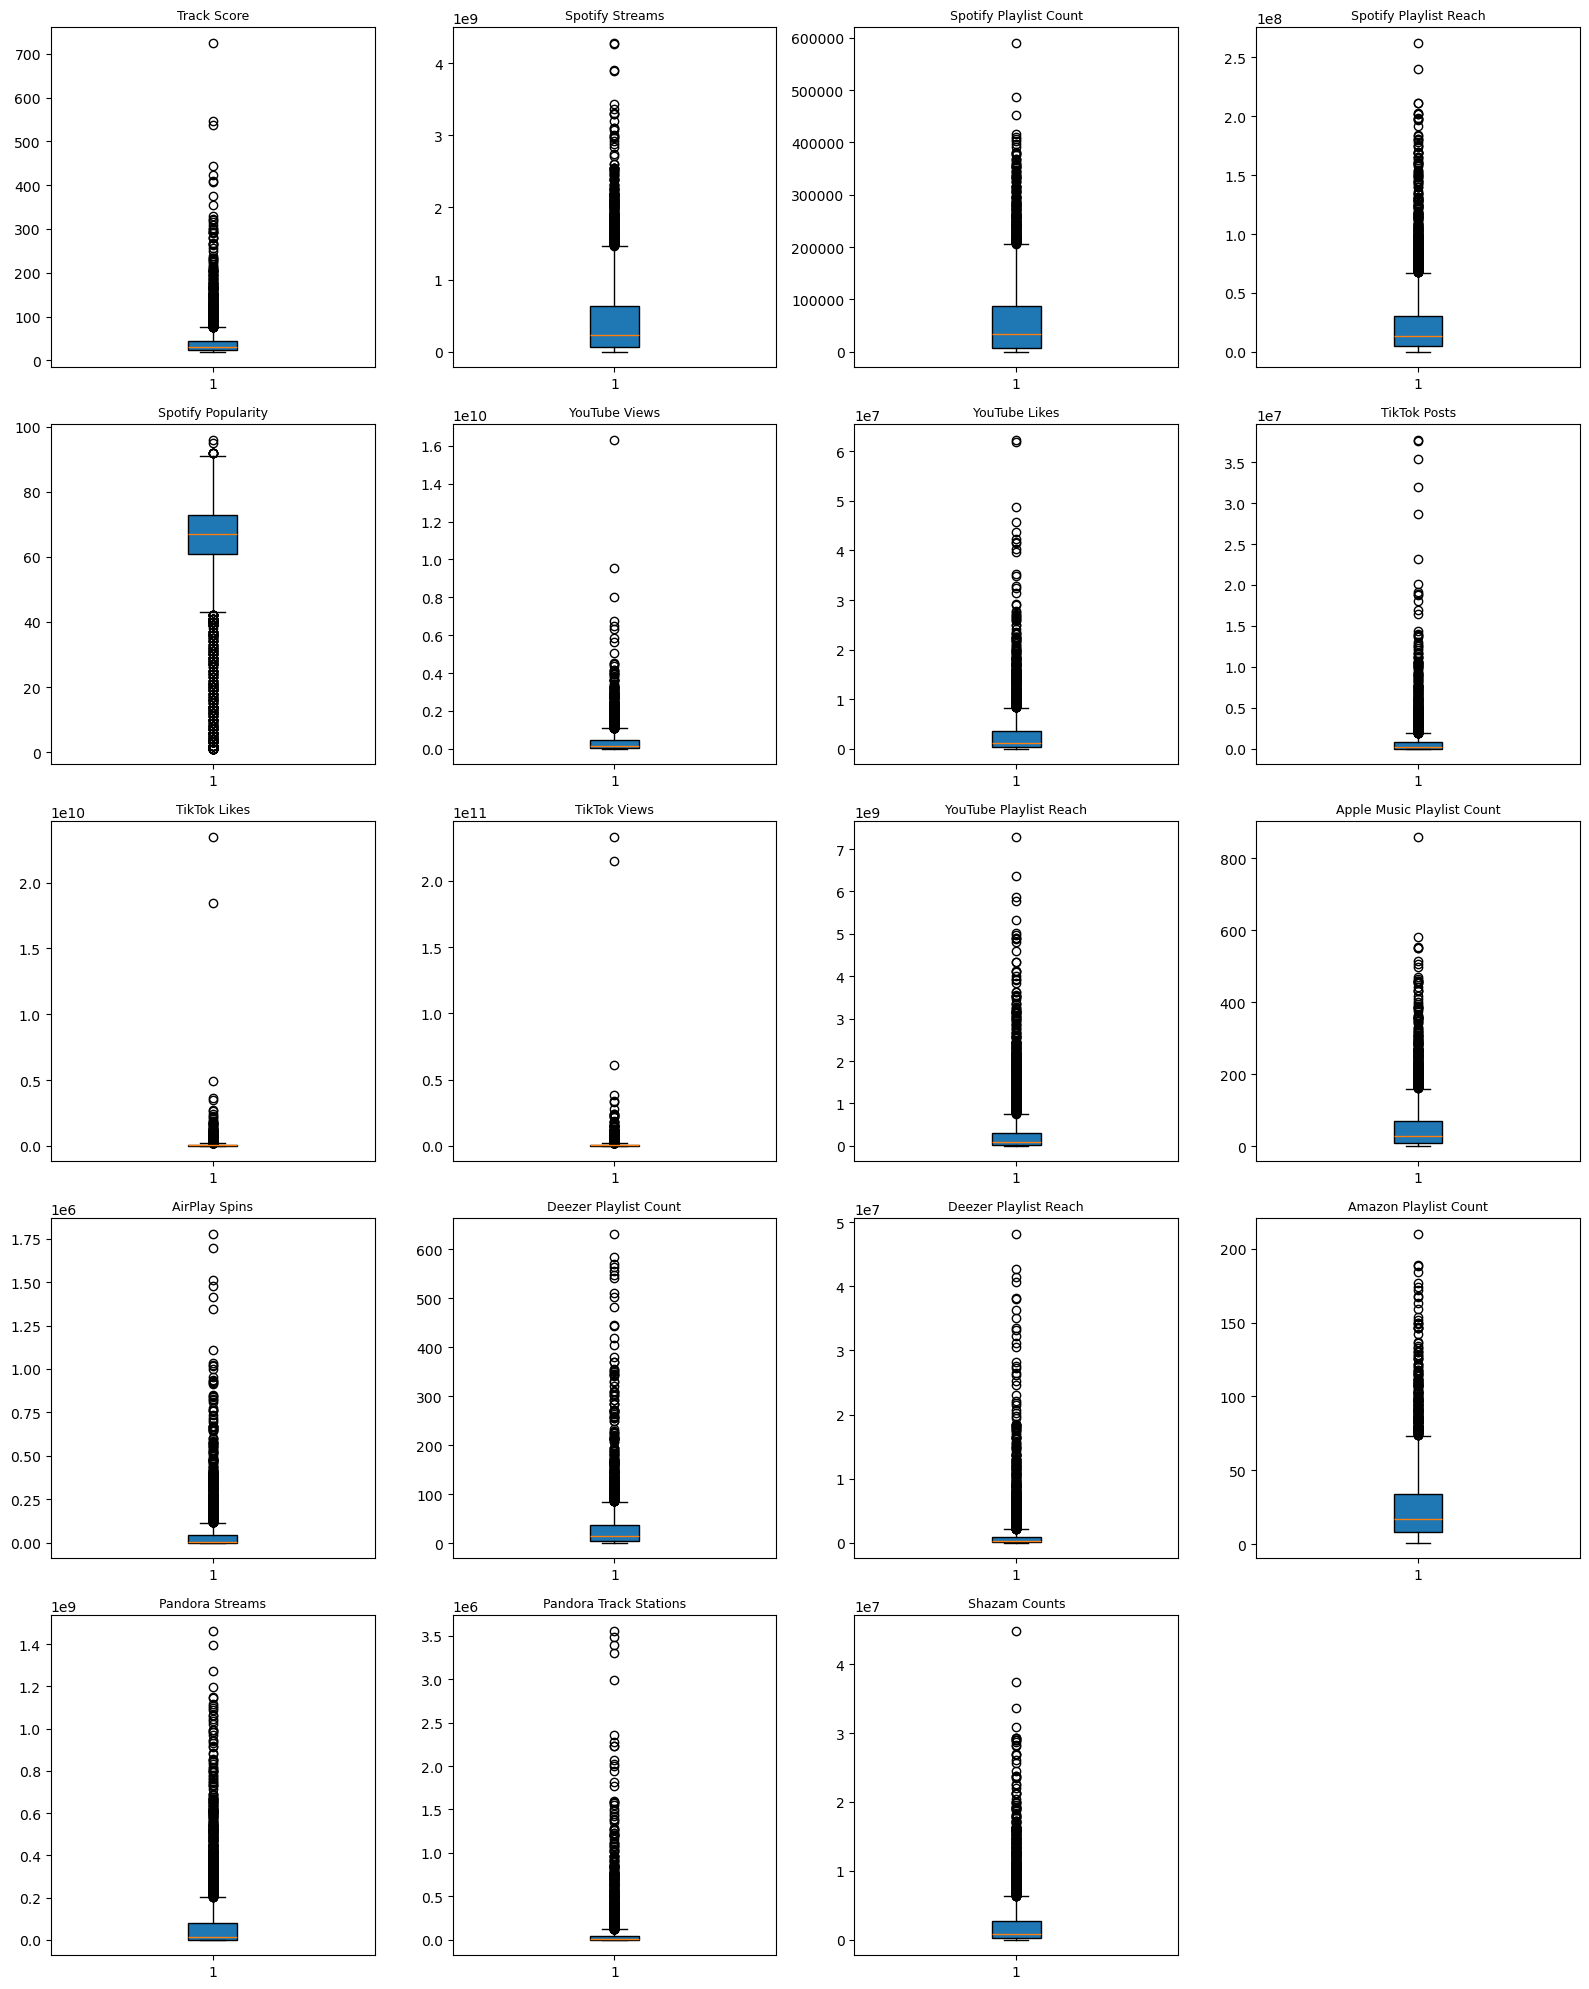

In [65]:
features = df.select_dtypes(include="number").columns.drop(
    ["All Time Rank", "Explicit Track", "release_year"], errors="ignore"
)
features = [c for c in features if not c.startswith("log_")]

n_rows = -(-len(features) // 4)   # round up
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, features):
    ax.boxplot(df[col].dropna(), patch_artist=True)
    ax.set_title(col, fontsize=9)

for ax in axes[len(features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [67]:
rows = []
for col in features:   # `features` was defined in the all-column boxplot cell
    s = df[col].dropna()
    p25, p75 = s.quantile(0.25), s.quantile(0.75)
    iqr = p75 - p25
    lower_limit, upper_limit = p25 - 1.5 * iqr, p75 + 1.5 * iqr
    n_low, n_up = (s < lower_limit).sum(), (s > upper_limit).sum()
    rows.append({
        "column": col,
        "percentile25": p25,
        "percentile75": p75,
        "lower_limit": lower_limit,
        "upper_limit": upper_limit,
        "lower_outliers": n_low,
        "upper_outliers": n_up,
        "pct_outliers": round((n_low + n_up) / len(s) * 100, 1),
        "skew": round(s.skew(), 1),
    })

pd.options.display.float_format = "{:,.1f}".format
pd.DataFrame(rows).set_index("column")


,percentile25,percentile75,lower_limit,upper_limit,lower_outliers,upper_outliers,pct_outliers,skew
column,,,,,,,,
Track Score,23.3,44.4,-8.3,76.0,0,392,8.7,5.8
Spotify Streams,"70,354,552.0","629,102,459.0","-767,767,308.5","1,467,224,319.5",0,289,6.4,2.0
Spotify Playlist Count,"7,360.0","86,990.0","-112,085.0","206,435.0",0,221,4.9,1.8
Spotify Playlist Reach,"5,116,146.0","30,030,265.0","-32,255,032.5","67,401,443.5",0,373,8.3,2.6
Spotify Popularity,61.0,73.0,43.0,91.0,313,8,8.5,-2.1
YouTube Views,"40,307,290.2","458,993,459.2","-587,721,963.2","1,087,022,712.8",0,416,9.9,6.2
YouTube Likes,"409,950.0","3,577,858.0","-4,341,912.0","8,329,720.0",0,349,8.3,4.3
TikTok Posts,"38,099.8","786,642.5","-1,084,714.4","1,909,456.6",0,416,12.2,7.2
TikTok Likes,"5,838,518.0","93,284,184.0","-125,329,981.0","224,452,683.0",0,406,11.3,32.4


In [68]:
# Are the extreme values genuine? Top 3 per column

for col in features:
    print(col)
    display(df.nlargest(3, col)[["Track", "Artist", col]])
    

Track Score


,Track,Artist,Track Score
0,MILLION DOLLAR BABY,Tommy Richman,725.4
1,Not Like Us,Kendrick Lamar,545.9
2,i like the way you kiss me,Artemas,538.4


Spotify Streams


,Track,Artist,Spotify Streams
55,Blinding Lights,The Weeknd,"4,281,468,720.0"
4254,Blinding Lights,xSyborg,"4,261,328,190.0"
53,Shape of You,Ed Sheeran,"3,909,458,734.0"


Spotify Playlist Count


,Track,Artist,Spotify Playlist Count
55,Blinding Lights,The Weeknd,"590,392.0"
70,Heat Waves,Glass Animals,"486,278.0"
26,STAY (with Justin Bieber),The Kid LAROI,"451,732.0"


... (28 outputs left out)

Pandora Track Stations


,Track,Artist,Pandora Track Stations
2107,All I Want for Christmas Is You,Mariah Carey,"3,556,791.0"
2665,Sex Music,Tank,"3,482,168.0"
859,Sexy And I Know It,LMFAO,"3,395,379.0"


Shazam Counts


,Track,Artist,Shazam Counts
39,Dance Monkey,Tones And I,"44,842,636.0"
472,Somebody That I Used To Know,Gotye,"37,339,828.0"
3560,Let Her Go,Passenger,"33,584,600.0"


**Conclusion:** Outliers were kept. The extreme values are genuine hits (e.g. Blinding Lights), not errors, and they are the most important songs for the TikTok–Spotify question. 

Most numeric columns are strongly right-skewed (skew well above 1), which is expected for popularity data where a few hits dominate. 

# Save the files back into directory/folder

In [71]:
df.to_csv("spotify_clean.csv", index=False)